# Detección de audios naturales y sintéticos

El proyecto busca clasificar audios naturales y sintéticos mediante
la fusión de las puntuaciones generadas por cuatro modelos DenseNet121,
correspondientes a las representaciones LOG, MEL, DWT y CQT.

Cada audio se representará mediante cuatro puntuaciones de
fake_probability, conservadas en el rango de 0 a 100.

La etiqueta verdadera se codificará como:
- 0: audio natural (real).
- 1: audio sintético (fake).

# Carga y preparación de los datos

Se carga el archivo original y se revisan su estructura, los valores
faltantes, los registros duplicados y las etiquetas disponibles.

In [6]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [7]:
data_path = Path("data/fake_densenet121.csv")

data = pd.read_csv(data_path)

display(data.head())

,architecture,transform,audio,fake_probability,prediction,ground_truth
0,densenet121,cqt,1.wav,0.08,real,fake
1,densenet121,dwt,1.wav,0.51,real,fake
2,densenet121,log,1.wav,10.73,real,fake
3,densenet121,mel,1.wav,0.02,real,fake
4,densenet121,cqt,10.wav,2.65,real,fake


In [8]:
print("Filas y columnas:", data.shape)

data.info()

Filas y columnas: (2568, 6)
<class 'pandas.DataFrame'>
RangeIndex: 2568 entries, 0 to 2567
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   architecture      2568 non-null   str    
 1   transform         2568 non-null   str    
 2   audio             2568 non-null   str    
 3   fake_probability  2568 non-null   float64
 4   prediction        2568 non-null   str    
 5   ground_truth      2568 non-null   str    
dtypes: float64(1), str(5)
memory usage: 120.5 KB


In [9]:
print("Valores faltantes por columna:")
display(data.isna().sum())

print("Filas duplicadas:", data.duplicated().sum())

print(
    "Pares audio-representación duplicados:",
    data.duplicated(subset=["audio", "transform"]).sum()
)

print("Etiquetas verdaderas:")
display(data["ground_truth"].value_counts())

print("Representaciones disponibles:")
display(data["transform"].value_counts())

print("Rango de las puntuaciones:")
display(data["fake_probability"].agg(["min", "max"]))

Valores faltantes por columna:


architecture        0
transform           0
audio               0
fake_probability    0
prediction          0
ground_truth        0
dtype: int64

Filas duplicadas: 0
Pares audio-representación duplicados: 0
Etiquetas verdaderas:


ground_truth
fake    2568
Name: count, dtype: int64

Representaciones disponibles:


transform
cqt    642
dwt    642
log    642
mel    642
Name: count, dtype: int64

Rango de las puntuaciones:


min      0.0
max    100.0
Name: fake_probability, dtype: float64

In [10]:
representations = ["log", "mel", "dwt", "cqt"]

assert not data.isna().any().any(), "Existen valores faltantes."

assert not data.duplicated(
    subset=["audio", "transform"]
).any(), "Hay puntuaciones repetidas para un mismo audio."

assert set(data["transform"]) == set(representations), (
    "Las representaciones no coinciden con las esperadas."
)

assert data["fake_probability"].between(0, 100).all(), (
    "Existen puntuaciones fuera del rango de 0 a 100."
)

assert data["ground_truth"].isin(["real", "fake"]).all(), (
    "Existen etiquetas desconocidas."
)

assert data.groupby("audio")["transform"].nunique().eq(4).all(), (
    "Algún audio no tiene las cuatro representaciones."
)

assert data.groupby("audio")["ground_truth"].nunique().eq(1).all(), (
    "Algún audio tiene etiquetas verdaderas contradictorias."
)

print("Comprobaciones completadas.")

Comprobaciones completadas.


# Organización de los datos

El archivo original contiene cuatro registros por audio.
Se reorganizan las puntuaciones para obtener una sola fila por audio,
con las columnas LOG, MEL, DWT y CQT y su etiqueta verdadera.

In [11]:
# Una columna por representación.
audio_table = data.pivot(
    index="audio",
    columns="transform",
    values="fake_probability"
)

audio_table = audio_table[representations]
audio_table.columns = ["LOG", "MEL", "DWT", "CQT"]

# Una etiqueta verdadera por audio.
labels = data.groupby("audio")["ground_truth"].first()

audio_table = audio_table.join(labels).reset_index()
audio_table.columns.name = None

# Codificación de la clase.
audio_table["target"] = audio_table["ground_truth"].map({
    "real": 0,
    "fake": 1
})

# Número utilizado para ordenar y dividir los audios.
audio_table["audio_number"] = (
    audio_table["audio"]
    .str.extract(r"^(\d+)\.wav$", expand=False)
    .astype(int)
)

audio_table = (
    audio_table
    .sort_values("audio_number")
    .reset_index(drop=True)
)

display(audio_table.head())

print("Total de audios:", len(audio_table))

,audio,LOG,MEL,DWT,CQT,ground_truth,target,audio_number
0,1.wav,10.73,0.02,0.51,0.08,fake,1,1
1,2.wav,84.34,0.56,17.48,0.67,fake,1,2
2,3.wav,63.58,0.15,1.33,14.12,fake,1,3
3,4.wav,88.24,11.55,1.19,1.72,fake,1,4
4,5.wav,26.95,0.06,1.51,2.11,fake,1,5


Total de audios: 642


# División de los datos

Se aplica la partición indicada en la guía:

- Entrenamiento: audios numerados del 1 al 450.
- Validación: audios numerados desde el 451.

El conjunto de validación se reserva para evaluar la solución final.
No se utilizará para seleccionar modelos, parámetros ni umbrales.

In [12]:
train_data = audio_table[
    audio_table["audio_number"].between(1, 450)
].copy()

validation_data = audio_table[
    audio_table["audio_number"] >= 451
].copy()

assert len(train_data) + len(validation_data) == len(audio_table), (
    "Hay audios que quedaron fuera de la partición."
)

assert set(train_data["audio"]).isdisjoint(validation_data["audio"]), (
    "Existen audios compartidos entre los conjuntos."
)

split_summary = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación"],
    "Cantidad de audios": [len(train_data), len(validation_data)]
})

display(split_summary)

print("Clases en entrenamiento:")
display(train_data["ground_truth"].value_counts())

print("Clases en validación:")
display(validation_data["ground_truth"].value_counts())

,Conjunto,Cantidad de audios
0,Entrenamiento,450
1,Validación,192


Clases en entrenamiento:


ground_truth
fake    450
Name: count, dtype: int64

Clases en validación:


ground_truth
fake    192
Name: count, dtype: int64

In [13]:
features = ["LOG", "MEL", "DWT", "CQT"]

X_train = train_data[features]
y_train = train_data["target"]

X_val = validation_data[features]
y_val = validation_data["target"]

print("Entradas de entrenamiento:", X_train.shape)
print("Entradas de validación:", X_val.shape)

if y_train.nunique() < 2 or y_val.nunique() < 2:
    print(
        "Pendiente: incorporar y revisar los datos naturales. "
        "La evaluación de ambas clases todavía no es posible."
    )

Entradas de entrenamiento: (450, 4)
Entradas de validación: (192, 4)
Pendiente: incorporar y revisar los datos naturales. La evaluación de ambas clases todavía no es posible.


# Análisis exploratorio

Se describe la distribución de clases y de las puntuaciones del
conjunto de entrenamiento.

El análisis es provisional porque el archivo disponible contiene
únicamente audios sintéticos.

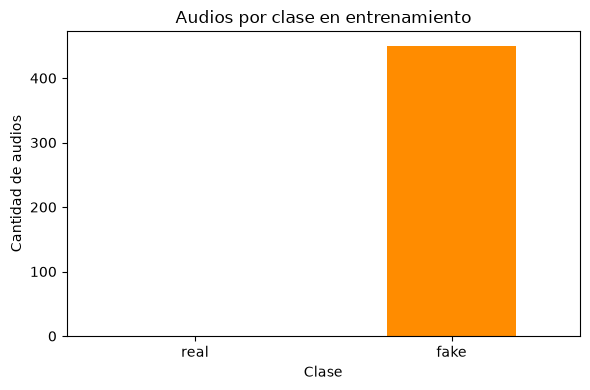

In [14]:
class_counts = (
    train_data["ground_truth"]
    .value_counts()
    .reindex(["real", "fake"], fill_value=0)
)

ax = class_counts.plot.bar(
    figsize=(6, 4),
    color=["steelblue", "darkorange"],
    rot=0
)

ax.set_title("Audios por clase en entrenamiento")
ax.set_xlabel("Clase")
ax.set_ylabel("Cantidad de audios")

plt.tight_layout()
plt.show()

In [15]:
display(X_train.describe())

,LOG,MEL,DWT,CQT
count,450.000000,450.000000,450.000000,450.000000
mean,62.437333,4.604400,16.154333,24.144733
std,40.405544,12.637815,23.217679,31.360074
min,0.000000,0.000000,0.020000,0.000000
25%,16.355000,0.040000,1.510000,0.732500
50%,84.000000,0.265000,5.010000,6.625000
75%,98.957500,1.810000,18.802500,43.052500
max,100.000000,98.100000,99.150000,99.690000


El conjunto de entrenamiento contiene 450 audios. LOG presenta una
puntuación promedio de 62,44 y una mediana de 84, mientras que MEL,
DWT y CQT tienen medianas de 0,265, 5,01 y 6,625, respectivamente.

Estos valores coinciden con lo observado en los histogramas: LOG
asigna puntuaciones altas a una mayor proporción de los audios,
mientras que en las otras representaciones predominan valores bajos.

Como todos los audios disponibles son sintéticos, este análisis
describe únicamente esa clase y deberá complementarse con los datos
de audios naturales.

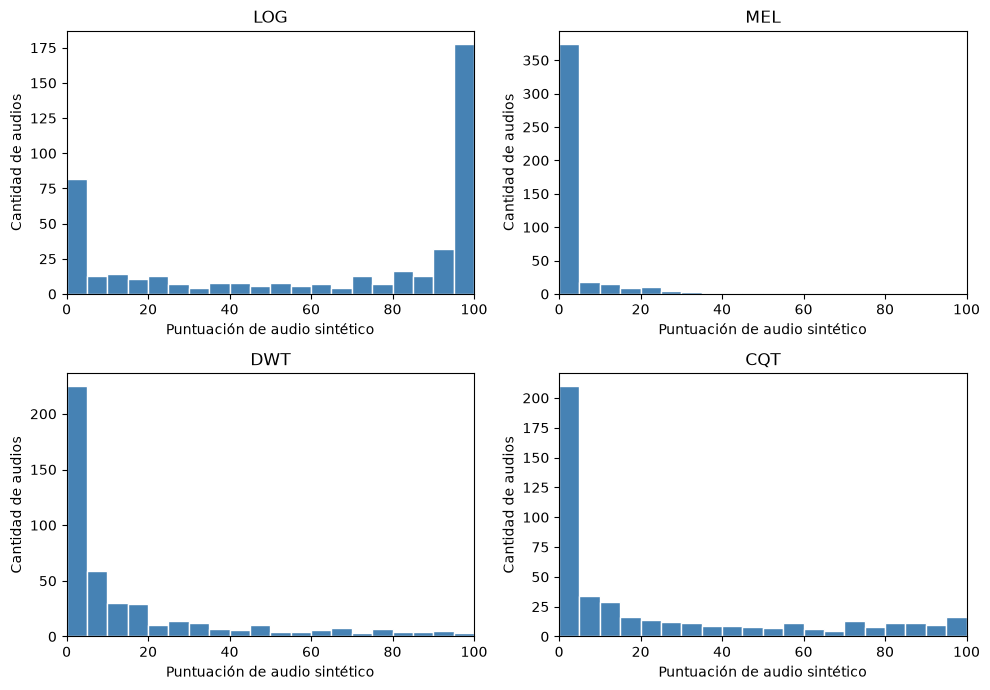

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for representation, ax in zip(features, axes.flat):
    ax.hist(
        X_train[representation],
        bins=20,
        range=(0, 100),
        color="steelblue",
        edgecolor="white"
    )

    ax.set_title(representation)
    ax.set_xlabel("Puntuación de audio sintético")
    ax.set_ylabel("Cantidad de audios")
    ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

Las puntuaciones del conjunto de entrenamiento presentan distribuciones
diferentes según la representación. LOG muestra concentraciones en ambos
extremos, con una presencia importante de valores cercanos a 100.
MEL, DWT y CQT concentran principalmente sus puntuaciones cerca de 0.

Dado que los audios disponibles están etiquetados como sintéticos,
las puntuaciones bajas apuntan hacia una clase distinta de la verdadera.

# Evaluación de modelos individuales

# Método de fusión

# Evaluación y conclusiones